In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv('autofarefixer_practice_data.csv')
print(df.shape); print(df.isna().sum().sum(), 'missing values'); df.describe().round(2)

(1500, 8)
0 missing values


,distance_km,hour,is_night,is_peak,rain,wait_min,meter_fare,actual_fare
count,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00
mean,5.79,11.22,0.29,0.27,0.15,2.50,89.44,102.47
std,3.96,6.92,0.46,0.45,0.35,2.75,54.47,62.08
min,0.50,0.00,0.00,0.00,0.00,0.00,30.00,30.00
25%,2.95,5.00,0.00,0.00,0.00,0.60,48.86,57.68
50%,5.02,11.00,0.00,0.00,0.00,1.60,77.88,88.72
75%,7.67,17.00,1.00,1.00,0.00,3.40,114.98,131.15
max,27.17,23.00,1.00,1.00,1.00,20.00,387.98,409.02


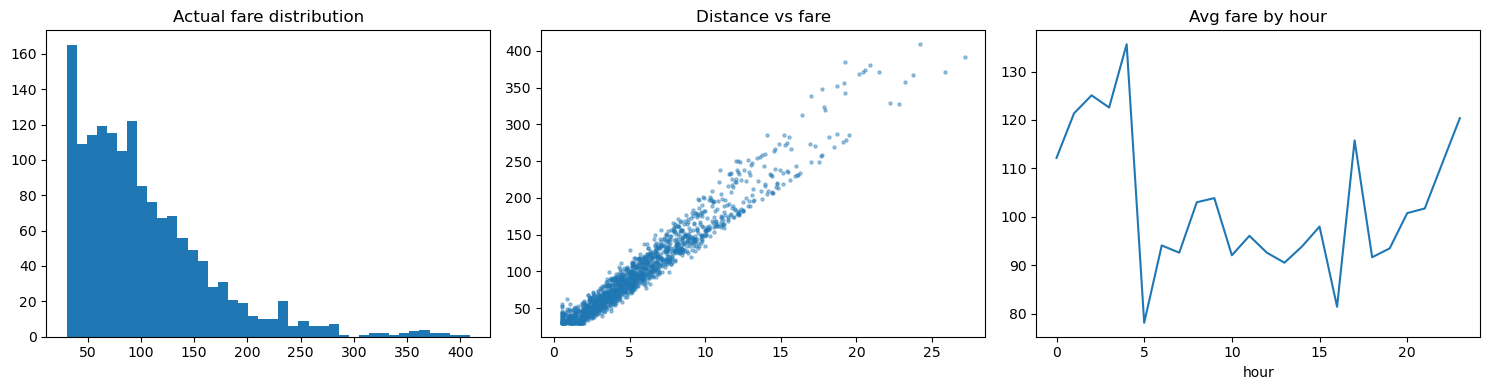

,distance_km,hour,is_night,is_peak,rain,wait_min,meter_fare,actual_fare
distance_km,1.00,-0.01,0.04,-0.01,-0.00,0.00,1.00,0.97
hour,-0.01,1.00,-0.37,0.31,0.03,0.06,-0.01,-0.06
is_night,0.04,-0.37,1.00,-0.40,0.03,-0.13,0.04,0.19
is_peak,-0.01,0.31,-0.40,1.00,-0.05,0.31,-0.01,-0.03
rain,-0.00,0.03,0.03,-0.05,1.00,-0.01,-0.00,0.06
wait_min,0.00,0.06,-0.13,0.31,-0.01,1.00,0.00,0.05
meter_fare,1.00,-0.01,0.04,-0.01,-0.00,0.00,1.00,0.97
actual_fare,0.97,-0.06,0.19,-0.03,0.06,0.05,0.97,1.00


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df.actual_fare, bins=40); ax[0].set_title('Actual fare distribution')
ax[1].scatter(df.distance_km, df.actual_fare, s=5, alpha=0.4); ax[1].set_title('Distance vs fare')
df.groupby('hour').actual_fare.mean().plot(ax=ax[2], title='Avg fare by hour')
plt.tight_layout(); plt.show()
df.corr().round(2)

In [3]:
features = ['distance_km', 'hour', 'is_night', 'is_peak', 'rain', 'wait_min']
X, y = df[features], df['actual_fare']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
def report(name, pred):
    mae = mean_absolute_error(yte, pred)
    rmse = np.sqrt(mean_squared_error(yte, pred))
    r2 = r2_score(yte, pred)
    print(f'{name:<22} MAE={mae:6.2f}  RMSE={rmse:6.2f}  R2={r2:.3f}')
    return dict(model=name, MAE=mae, RMSE=rmse, R2=r2)
results = []
results.append(report('Baseline (meter fare)', df.loc[yte.index, 'meter_fare']))
lr = LinearRegression().fit(Xtr, ytr)
results.append(report('Linear Regression', lr.predict(Xte)))
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
results.append(report('Random Forest', rf.predict(Xte)))
pd.DataFrame(results).round(3)

Baseline (meter fare)  MAE= 14.84  RMSE= 21.07  R2=0.904
Linear Regression      MAE=  7.12  RMSE=  9.69  R2=0.980


Random Forest          MAE=  6.24  RMSE=  8.38  R2=0.985


,model,MAE,RMSE,R2
0,Baseline (meter fare),14.843,21.071,0.904
1,Linear Regression,7.124,9.688,0.980
2,Random Forest,6.239,8.381,0.985


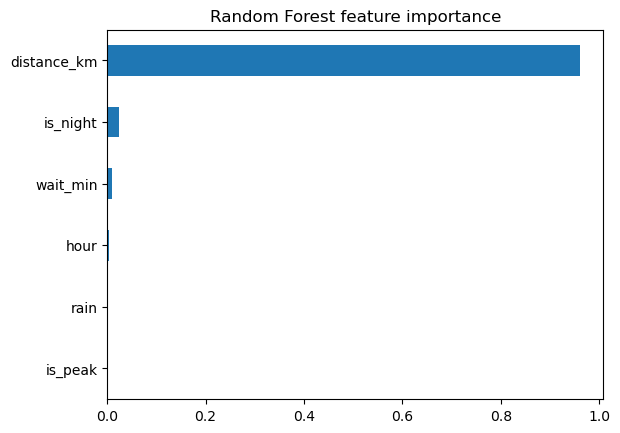

In [4]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind='barh', title='Random Forest feature importance'); plt.show()